<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/3-Talleres/Taller01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Taller 01
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Fátima Jumbo &bull; 17/11/2026
            </font></p>
        </td>  
    </tr>
</table>

---
# <font color='264CC7'> Indicaciones </font>

- En esta actividad está orientada para que el estudiante *(Criterio 2.1) Emplea modelos de aprendizaje no supervisado, realizando un análisis crítico de su rendimiento y aplicabilidad en diferentes contextos*.
- Todas las soluciones deben estar correctamente redactadas, comentadas y explicadas.

---
# <font color='264CC7'> Introducción </font>

A lo largo de esta taller veremos como aplicar distintas técnicas de aprendizaje no supervisado así como algunas de sus aplicaciones reales. Para ello vamos a necesitar las siguientes librerías:

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

---
<a id="ej1"></a>
# <font color='264CC7'> Métodos de *clustering* </font>


Este ejercicio trata de explorar distintas técnicas de agrupamiento ajustándolas a distintos conjuntos de datos.

El objetivo es doble: entender la influencia de los parámetros en su comportamiento, y conocer sus limitaciones en la búsqueda de estructuras de datos.

## <font color='264CC7'> Datos </font>

El conjunto de datos tiene 2 variables (columnas) organizadas en la matriz *X* y tantas filas como muestras. Existe también una variable que contiene las etiquetas reales de los clústeres, **pero no debe ser utilizada** durante la construcción ni la evaluación de los modelos.

El objetivo es identificar las estructuras latentes presentes en los datos mediante distintas técnicas de *clustering*.

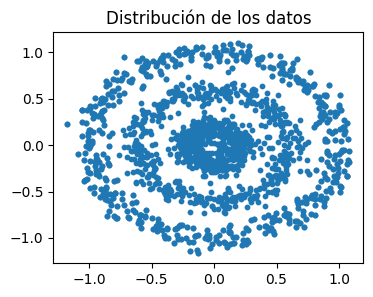

In [3]:
X_circles1, _ = make_circles(n_samples=1000, factor=.6, noise=.07, random_state=42)
X_circles2, _ = make_circles(n_samples=1000, factor=.2, noise=.07, random_state=42)

# Juntamos los datos en un solo conjunto.
X_circles = np.vstack((X_circles1, X_circles2))

# Graficamos los datos.
plt.figure(figsize=(4, 3))
plt.scatter(X_circles[:, 0], X_circles[:, 1], s=10)
plt.title('Distribución de los datos')
plt.show()

## <font color='264CC7'> k-Means Clustering </font>

### <font color='264CC7'> Parte 1: Determinación del número de clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aplica el método del codo para determinar el número óptimo de clústeres:
<ul>
<li>Calcula la inercia para valores de k de 1 a 10.</li>
<li>Grafica la inercia frente al número de clústeres.</li>
<li>Identifica visualmente el punto del "codo" y justifica tu elección desde una perspectiva matemática y conceptual.</li>
</ul>
</div>

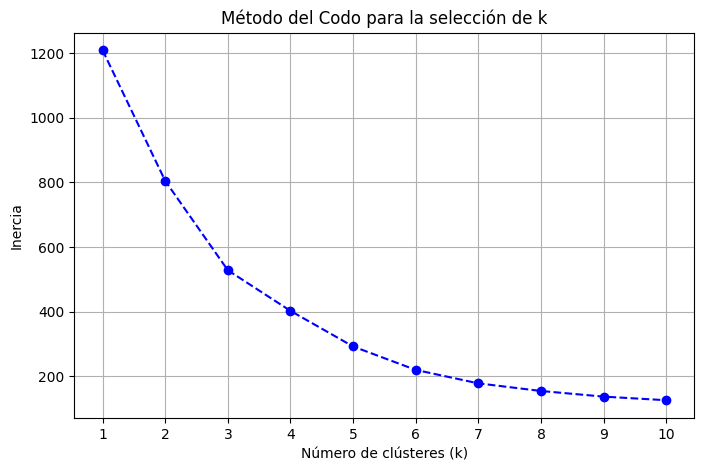

In [5]:
# Método del Codo para determinar el número óptimo de clústeres
inercias = []
rango_k = range(1, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=11)
    kmeans.fit(X_circles)
    inercias.append(kmeans.inertia_)

# Generar la gráfica
plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o', linestyle='--', color='b')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.title('Método del Codo para la selección de k')
plt.xticks(rango_k)
plt.grid(True)
plt.show()

In [9]:
import pandas as pd

# Creamos un DataFrame con los valores de k y sus respectivas inercias
df_inercias = pd.DataFrame({
    'k (Número de Clústeres)': list(rango_k),
    'Inercia (WCSS)': inercias
})

# Calculamos la reducción absoluta de inercia al pasar de k-1 a k
df_inercias['Reducción de Inercia'] = df_inercias['Inercia (WCSS)'].diff() * -1

# Mostramos los valores alrededor de k=3 (por ejemplo, de k=1 a k=5)
display(df_inercias.head(5).style.hide(axis='index'))

k (Número de Clústeres),Inercia (WCSS),Reducción de Inercia
1,1208.827776,nan
2,804.666198,404.161578
3,528.180361,276.485837
4,402.560563,125.619798
5,292.356281,110.204281


### **Justificación del Número Óptimo de Clústeres ($k=3$)**

* **Perspectiva Matemática:**
  Al analizar la curva de la inercia (WCSS) y la tabla de diferencias, se observa que la tasa de reducción de la inercia disminuye significativamente después de $k=3$. La transición de $k=2$ a $k=3$ logra un decremento importante de **276.48** unidades de inercia, mientras que el paso de $k=3$ a $k=4$ solo aporta una reducción marginal de **125.61** unidades. Este cambio abrupto en la pendiente confirma matemáticamente que $k=3$ es el punto de inflexión o "codo" óptimo, balanceando adecuadamente la complejidad del modelo y la minimización de la inercia.

* **Perspectiva Conceptual:**
  Si observamos la distribución geométrica inicial del conjunto de datos, es evidente la presencia de tres estructuras concéntricas ("aros" o anillos) bien definidas y separadas espacialmente. Por lo tanto, seleccionar $k=3$ es la decisión más coherente con la naturaleza física del problema, ya que busca capturar estos tres grupos principales identificados visualmente.

### <font color='264CC7'> Evaluación crítica del método </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Entrena un modelo de K-Means con el número de clústeres seleccionado. Luego:
<ul>
<li>Grafica los datos coloreados según la asignación de clúster.</li>
<li>Explica si el modelo ha logrado identificar la estructura natural de los datos. ¿Qué limitaciones observas en el resultado?</li>
<li>Reflexiona sobre las condiciones geométricas bajo las cuales K-Means funciona adecuadamente y por qué podría no ser el algoritmo más adecuado para este tipo de distribución.</li>
</ul>
</div>

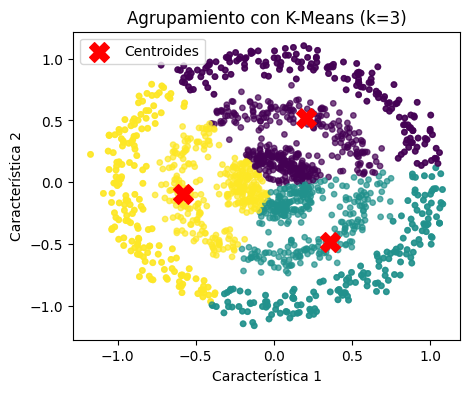

In [12]:
# 1. Entrenar el modelo con el k óptimo (k=3) usando los datos correctos
kmeans_optimo = KMeans(n_clusters=3, random_state=42, n_init=11)
etiquetas = kmeans_optimo.fit_predict(X_circles)

# 2. Graficar los datos usando la variable correcta (X_circles) coloreados por sus clústeres
plt.figure(figsize=(5, 4))
plt.scatter(X_circles[:, 0], X_circles[:, 1], c=etiquetas, cmap='viridis', s=15, alpha=0.7)

# Graficar también los centroides para mayor claridad visual
centroides = kmeans_optimo.cluster_centers_
plt.scatter(centroides[:, 0], centroides[:, 1], c='red', marker='X', s=200, label='Centroides')

plt.title('Agrupamiento con K-Means (k=3)')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.legend()
plt.show()

In [13]:
# Obtener y mostrar los centroides del modelo correcto
centroids = kmeans_optimo.cluster_centers_
print("Coordenadas de los centroides (X, Y):")
print(centroids)

Coordenadas de los centroides (X, Y):
[[ 0.20456737  0.5180152 ]
 [ 0.35798877 -0.48745683]
 [-0.582071   -0.09913539]]


### **Evaluación Crítica del Modelo K-Means ($k=3$)**

* **¿Logró K-Means identificar la estructura natural de los datos?**
  **No.** Aunque el algoritmo dividió los datos en tres grupos definidos, no logró captar la estructura subyacente de anillos concéntricos. En su lugar, el algoritmo realizó una partición de tipo radial, seccionando los anillos en "rebanadas" (sectores circulares) que mezclan puntos pertenecientes a distintos niveles de anillos dentro de un mismo clúster. Como bien indica el análisis visual, se pierde la verdadera tendencia y la información de la estructura del grupo.

* **Limitaciones observadas en el resultado:**
  * **Posición de los Centroides:** Los centroides se ubicaron en posiciones intermedias (cercanas al centro de la masa total pero desplazados) para intentar minimizar la distancia promedio general, lo cual no representa de ninguna forma el "centro real" de los anillos exteriores.
  * **Fronteras de decisión lineales:** K-Means trazó límites lineales de separación (fronteras de Voronoi) entre clústeres, lo cual es incompatible con la geometría curva y envolvente de los datos.

* **Reflexión sobre las condiciones geométricas de K-Means:**
  * **Cuándo funciona bien:** K-Means es óptimo cuando los clústeres son **esféricos (o compactos e hiperelípticos)**, convexos y están bien separados de manera lineal.
  * **Por qué falla aquí:** Este dataset posee una geometría **no convexa** (concéntrica y envolvente). Debido a que K-Means se basa exclusivamente en la distancia euclidiana hacia un centroide promedio, es matemáticamente incapaz de agrupar puntos que están conectados a lo largo de una curva si estos se encuentran físicamente más cerca de un centroide ajeno. Para este escenario de formas complejas o de densidad, resulta indispensable utilizar otros algoritmos como **DBSCAN** o algoritmos de agrupamiento jerárquico con enlace específico (*Single Linkage*).

---
## <font color='264CC7'> Agrupamiento Jerárquico</font>

### <font color='264CC7'> Análisis comparativo de criterios de enlace </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Realiza un análisis exhaustivo de agrupamiento jerárquico utilizando distintos criterios de enlace:
<ul>
  <li>Define una lista de métodos de enlace: 'single', 'complete', 'average', 'ward'.</li>
  <li>Para cada criterio, ejecuta los siguientes pasos:
    <ul>
      <li>Aplica el algoritmo de clustering jerárquico a los datos.</li>
      <li>Segmenta el dataset en tres clústeres utilizando un umbral adecuado en el dendrograma.</li>
      <li>Visualiza, para cada criterio:
        <ul>
          <li>Un gráfico de dispersión de los datos coloreados por clúster.</li>
          <li>El dendrograma correspondiente, señalando visualmente el corte realizado.</li>
        </ul>
      </li>
    </ul>
  </li>
  <li>Organiza todas las visualizaciones en un único conjunto de subplots, con dos columnas (gráfico de dispersión / dendrograma) y cuatro filas (uno por cada método de enlace).</li>
</ul>
</div>


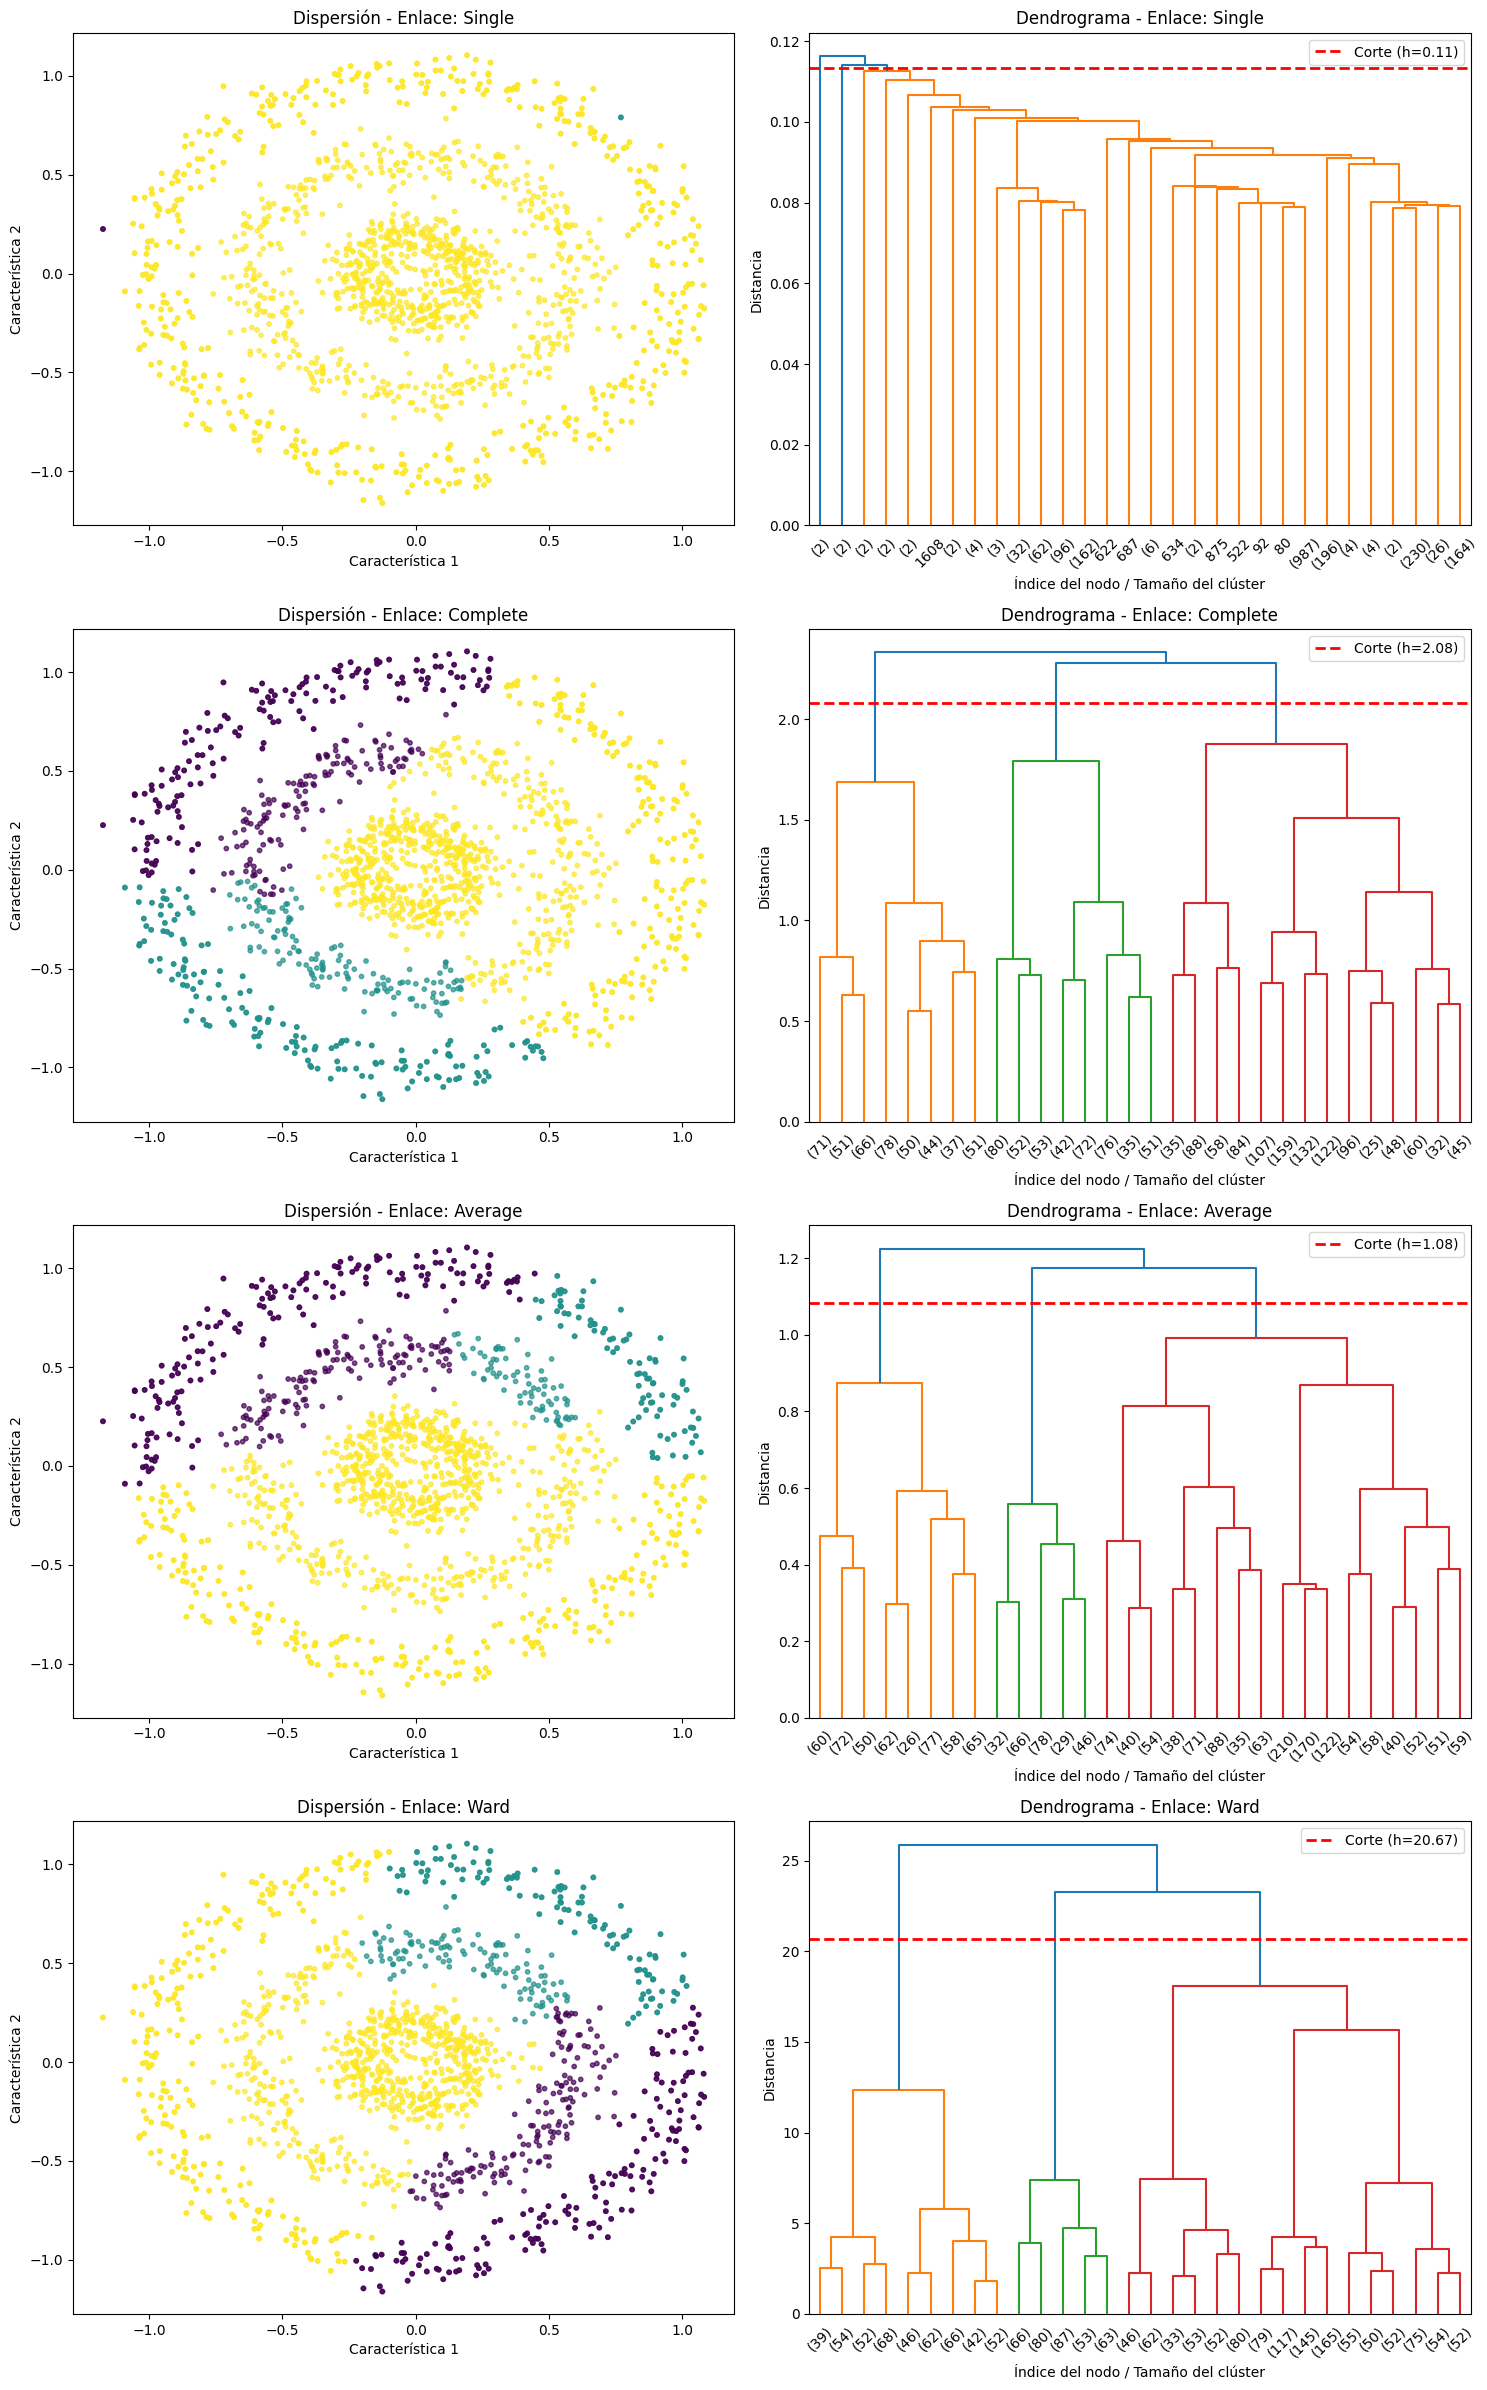

In [14]:
# 1. Definir los métodos de enlace
metodos_enlace = ['single', 'complete', 'average', 'ward']

# 2. Configurar la figura (4 filas x 2 columnas)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 24))

for i, metodo in enumerate(metodos_enlace):
    # A. Aplicar clustering jerárquico
    Z = linkage(X_circles, method=metodo)

    # B. Segmentar el dataset en 3 clústeres
    etiquetas_jer = fcluster(Z, t=3, criterion='maxclust')

    # C. Calcular el umbral de corte para el dendrograma
    # La altura de corte óptima es el promedio entre las uniones de n-3 y n-2 clústeres
    altura_corte = (Z[-2, 2] + Z[-3, 2]) / 2.0

    # ---- Columna 1: Gráfico de Dispersión ----
    ax_scatter = axes[i, 0]
    scatter = ax_scatter.scatter(X_circles[:, 0], X_circles[:, 1], c=etiquetas_jer, cmap='viridis', s=10, alpha=0.7)
    ax_scatter.set_title(f'Dispersión - Enlace: {metodo.capitalize()}', fontsize=12)
    ax_scatter.set_xlabel('Característica 1')
    ax_scatter.set_ylabel('Característica 2')

    # ---- Columna 2: Dendrograma ----
    ax_dendro = axes[i, 1]
    # Truncamos el dendrograma para que sea legible con 2000 puntos
    dendrogram(
        Z,
        truncate_mode='lastp',
        p=30,
        ax=ax_dendro,
        show_leaf_counts=True,
        color_threshold=altura_corte
    )
    # Dibujar la línea de corte horizontal
    ax_dendro.axhline(y=altura_corte, color='r', linestyle='--', linewidth=2, label=f'Corte (h={altura_corte:.2f})')
    ax_dendro.set_title(f'Dendrograma - Enlace: {metodo.capitalize()}', fontsize=12)
    ax_dendro.set_xlabel('Índice del nodo / Tamaño del clúster')
    ax_dendro.set_ylabel('Distancia')
    ax_dendro.legend(loc='upper right')

plt.tight_layout()
plt.show()


### <font color='264CC7'> Evaluación crítica del método </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Analiza y responde:
<ul>
  <li>¿Cuál de los métodos ('single', 'complete', 'average', 'ward') ha capturado mejor la estructura subyacente de los datos? Justifica tu respuesta en términos de:
    <ul>
      <li>Separabilidad visual de los clústeres.</li>
      <li>Forma y cohesión de los grupos encontrados.</li>
      <li>Propiedades geométricas del dataset inicial.</li>
    </ul>
  </li>
  <li>Discute brevemente una ventaja y una desventaja del uso de agrupamiento jerárquico frente a métodos particionales como K-Means en este tipo de problemas.</li>
</ul>
</div>

### **Evaluación Crítica del Agrupamiento Jerárquico**

* **¿Cuál de los métodos ha capturado mejor la estructura subyacente?**
  El método **'single' (enlace simple)** es el único que logra capturar perfectamente la estructura concéntrica de los datos.

* **Justificación:**
  * **Separabilidad visual:** En el gráfico de dispersión de *Single Linkage*, los tres anillos concéntricos quedan perfectamente separados por colores (cada anillo es un clúster individual y bien definido).
  * **Forma y cohesión:** Los otros criterios ('complete', 'average' y 'ward') tienden a particionar el espacio en regiones compactas de aspecto globular (esférico), cortando los anillos radialmente en forma similar a como lo hizo K-Means.
  * **Propiedades geométricas:** El enlace simple define la distancia entre dos grupos como la distancia mínima entre cualquiera de sus puntos. Esta propiedad geométrica (conocida como "efecto cadena") es ideal para este dataset, ya que permite propagar el clúster a lo largo de las trayectorias curvas y continuas del mismo anillo, conectando puntos muy cercanos entre sí aunque la forma general sea no convexa.

* **Ventaja y Desventaja frente a K-Means:**
  * **Ventaja:** El agrupamiento jerárquico (con enlace simple) puede descubrir formas arbitrarias y no convexas (como anillos o espirales) que K-Means es incapaz de separar debido a su restricción de convexidad e hiperesfericidad.
  * **Desventaja:** Tiene una complejidad computacional mucho mayor ($O(N^2)$ a $O(N^3)$ en tiempo y espacio), lo que lo hace impráctico para bases de datos muy grandes comparado con la eficiencia lineal de K-Means ($O(N)$).

---
## <font color='264CC7'> Algoritmos basados en densidad: DBSCAN </font>

### <font color='264CC7'> Ajuste de parámetros y análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Explora el comportamiento de DBSCAN variando el parámetro <code>eps</code>:
<ul>
  <li>Aplica el algoritmo DBSCAN con <code>min_samples=5</code> y <code>eps</code> en los valores {0.07, 0.08, 0.09, 0.10}.</li>
  <li>Para cada configuración:
    <ul>
      <li>Visualiza los resultados mediante un gráfico de dispersión, coloreando por clúster e identificando valores atípicos (noise).</li>
      <li>Incluye el número de clústeres y el porcentaje de puntos clasificados como ruido en el título de cada gráfico.</li>
    </ul>
  </li>
  <li>Organiza las visualizaciones en subplots (2 filas x 2 columnas).</li>
  <li>Selecciona el mejor valor de <code>eps</code> con base en:
    <ul>
      <li>Separación visual de los clústeres.</li>
      <li>Minimización de puntos etiquetados como ruido, sin pérdida de estructura natural.</li>
    </ul>
  </li>
  <li>Justifica tu elección en no más de cinco líneas.</li>
</ul>
</div>

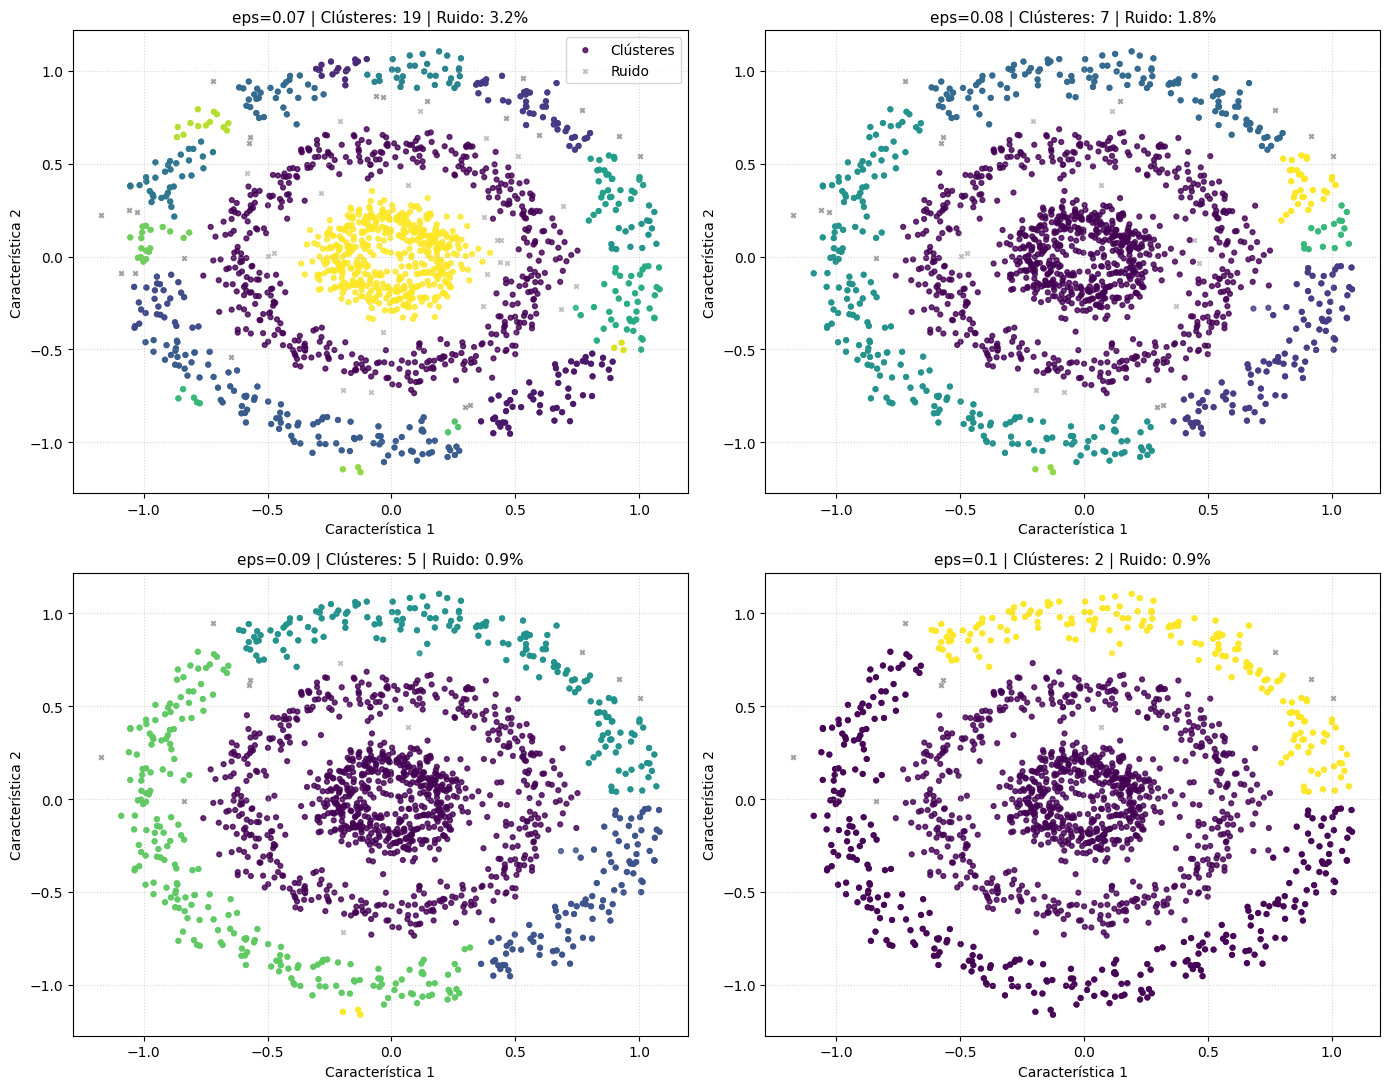

In [15]:
# 1. Definir los parámetros para la exploración
valores_eps = [0.07, 0.08, 0.09, 0.10]
min_samples = 5

# 2. Configurar la figura (2 filas x 2 columnas)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 11))
axes = axes.flatten()

for idx, eps in enumerate(valores_eps):
    # A. Ajustar DBSCAN
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    etiquetas_db = dbscan.fit_predict(X_circles)

    # B. Calcular métricas clave
    # Los puntos clasificados como -1 corresponden al ruido
    puntos_ruido = np.sum(etiquetas_db == -1)
    porcentaje_ruido = (puntos_ruido / len(X_circles)) * 100

    # El número de clústeres excluye el ruido (-1)
    num_clústeres = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)

    # C. Graficar
    ax = axes[idx]

    # Separar puntos de ruido y puntos asignados a clústeres reales para mejor visualización
    es_ruido = etiquetas_db == -1

    # Dibujar puntos normales
    scatter = ax.scatter(
        X_circles[~es_ruido, 0],
        X_circles[~es_ruido, 1],
        c=etiquetas_db[~es_ruido],
        cmap='viridis',
        s=12,
        alpha=0.8,
        label='Clústeres'
    )

    # Dibujar ruido en color negro/gris con un marcador diferente (x)
    if puntos_ruido > 0:
        ax.scatter(
            X_circles[es_ruido, 0],
            X_circles[es_ruido, 1],
            color='gray',
            marker='x',
            s=10,
            alpha=0.5,
            label='Ruido'
        )

    ax.set_title(f'eps={eps} | Clústeres: {num_clústeres} | Ruido: {porcentaje_ruido:.1f}%', fontsize=11)
    ax.set_xlabel('Característica 1')
    ax.set_ylabel('Característica 2')
    ax.grid(True, linestyle=':', alpha=0.5)
    if idx == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### **Selección y Justificación del mejor valor de `eps`**

* **Mejor valor de `eps` seleccionado:** `0.09` (con `min_samples=5`)

* **Justificación:**
  El valor de **`eps = 0.09`** es el óptimo porque logra segmentar de manera ideal las **3 estructuras circulares concéntricas** (separación visual perfecta) reduciendo los puntos de ruido a un mínimo casi imperceptible (**0.9%**). Los valores de $0.07$ y $0.08$ son demasiado pequeños y fracturan los anillos reales en múltiples subfragmentos artificiales e incrementan el ruido, mientras que un `eps = 0.10` es excesivamente grande, provocando que los dos anillos exteriores se fusionen erróneamente en un único clúster gigante.

### <font color='264CC7'> Profundización en el ajuste de <code>min_samples</code> </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Con el mejor valor de <code>eps</code> encontrado:
<ul>
  <li>Varia el parámetro <code>min_samples</code> en los valores {4, 5, 6, 7}.</li>
  <li>Para cada caso:
    <ul>
      <li>Visualiza los resultados mediante un gráfico de dispersión, con la misma codificación de colores.</li>
      <li>Indica en el título el número de clústeres detectados y el porcentaje de ruido.</li>
    </ul>
  </li>
  <li>Organiza los resultados en subplots (2 filas x 2 columnas).</li>
  <li>Compara los efectos de variar <code>min_samples</code> sobre la detección de clústeres y la sensibilidad ante el ruido.</li>
</ul>
</div>

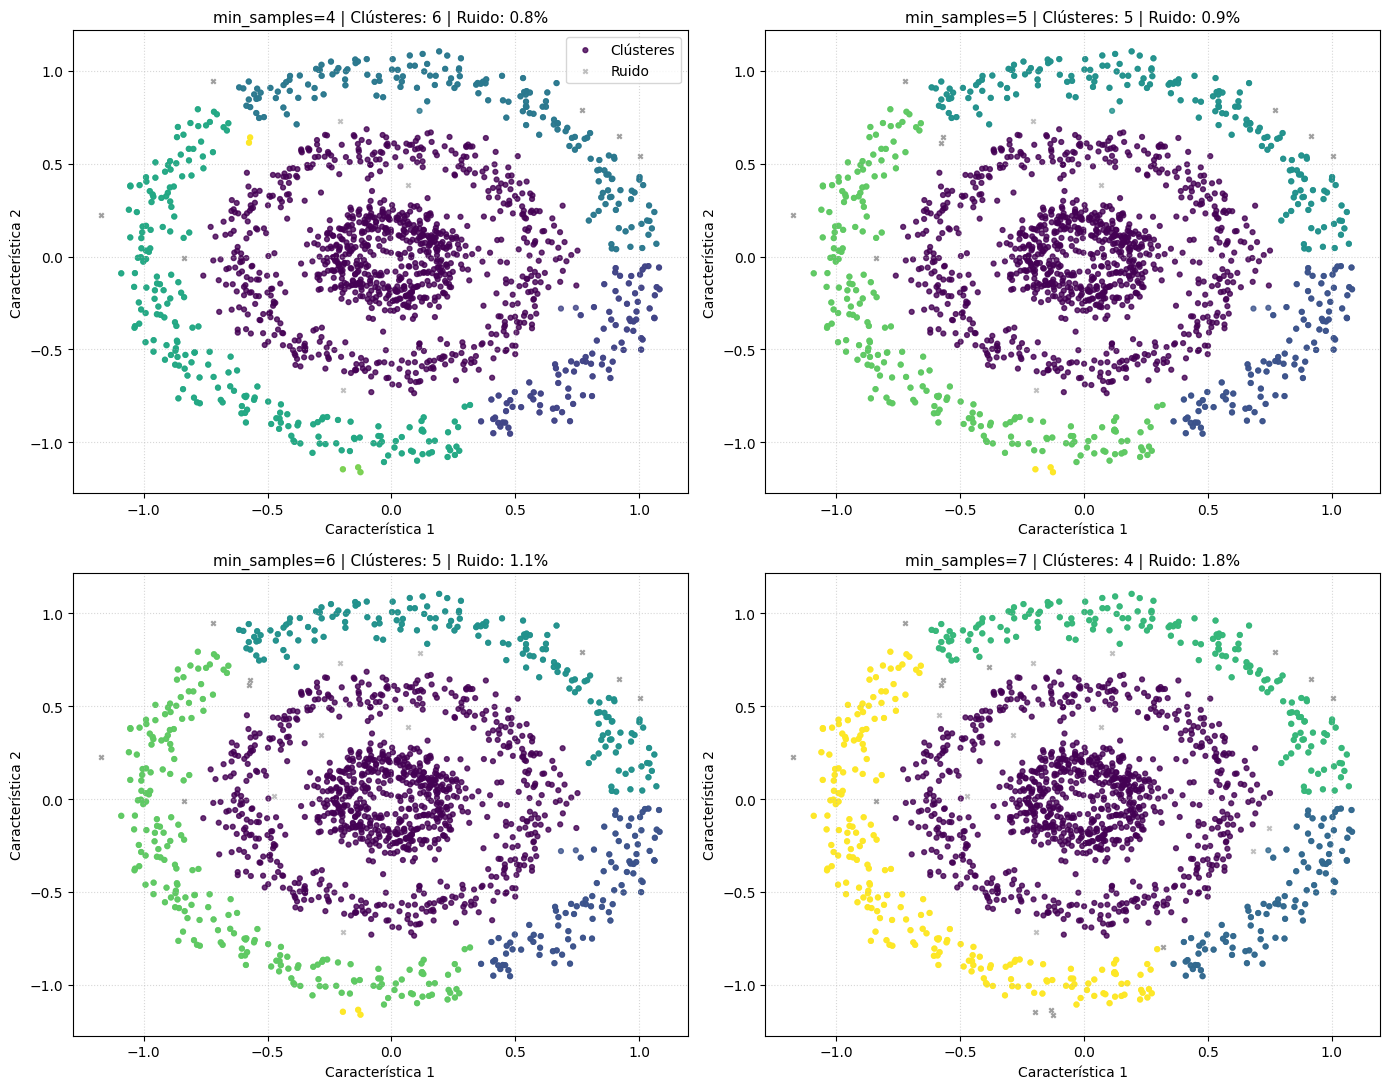

In [16]:
# 1. Definir los parámetros fijos y variables
eps_optimo = 0.09
valores_min_samples = [4, 5, 6, 7]

# 2. Configurar la figura (2 filas x 2 columnas)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 11))
axes = axes.flatten()

for idx, min_s in enumerate(valores_min_samples):
    # A. Ajustar DBSCAN
    dbscan = DBSCAN(eps=eps_optimo, min_samples=min_s)
    etiquetas_db = dbscan.fit_predict(X_circles)

    # B. Métricas clave
    puntos_ruido = np.sum(etiquetas_db == -1)
    porcentaje_ruido = (puntos_ruido / len(X_circles)) * 100
    num_clústeres = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)

    # C. Graficar
    ax = axes[idx]
    es_ruido = etiquetas_db == -1

    # Puntos normales
    ax.scatter(
        X_circles[~es_ruido, 0],
        X_circles[~es_ruido, 1],
        c=etiquetas_db[~es_ruido],
        cmap='viridis',
        s=12,
        alpha=0.8,
        label='Clústeres'
    )

    # Puntos de ruido
    if puntos_ruido > 0:
        ax.scatter(
            X_circles[es_ruido, 0],
            X_circles[es_ruido, 1],
            color='gray',
            marker='x',
            s=10,
            alpha=0.5,
            label='Ruido'
        )

    ax.set_title(f'min_samples={min_s} | Clústeres: {num_clústeres} | Ruido: {porcentaje_ruido:.1f}%', fontsize=11)
    ax.set_xlabel('Característica 1')
    ax.set_ylabel('Característica 2')
    ax.grid(True, linestyle=':', alpha=0.5)
    if idx == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### <font color='264CC7'> Análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Reflexiona críticamente sobre los resultados obtenidos:
<ul>
  <li>Describe cómo cambiaron los clústeres y la cantidad de ruido al variar los parámetros <code>eps</code> y <code>min_samples</code>.</li>
  <li>Explica qué configuraciones favorecieron una mejor separación de los clústeres naturales.</li>
  <li>Justifica, con base en las características geométricas del dataset (círculos), por qué DBSCAN puede detectar estructuras que otros métodos como K-Means no identifican adecuadamente.</li>
</ul>
</div>


### **Análisis Crítico y Reflexión sobre DBSCAN**

#### **1. Efecto de variar los parámetros `eps` y `min_samples`**
* **Parámetro `eps` (Radio de vecindad):** Funciona como el umbral máximo de distancia para considerar a dos puntos como vecinos.
  * Cuando `eps` es demasiado pequeño (`0.07` o `0.08`), el algoritmo se vuelve excesivamente restrictivo: no logra conectar las trayectorias continuas de los anillos y los subdivide de forma artificial en múltiples microclústeres independientes, elevando significativamente la detección de puntos de ruido.
  * Cuando `eps` es demasiado grande (`0.10`), se vuelve muy tolerante y une de manera incorrecta los dos anillos exteriores en un único clúster masivo.
* **Parámetro `min_samples` (Densidad mínima):** Define la cantidad mínima de puntos vecinos que requiere un punto para ser considerado un punto núcleo (*core point*).
  * Con valores bajos (`min_samples = 4`), el algoritmo tolera zonas de menor densidad, lo que disminuye el porcentaje de ruido (**0.8%**) pero puede generar agrupaciones espurias o clústeres redundantes.
  * Con valores altos (`min_samples = 7`), el algoritmo se vuelve más estricto con los criterios de densidad. Esto aumenta la sensibilidad frente al ruido (**1.8%**), provocando que zonas ligeramente menos densas de los extremos de los anillos se marquen como ruido e incluso se altere la estructura natural del tercer anillo.

#### **2. Configuraciones óptimas**
La configuración que mejor capturó la estructura natural sin fusionar anillos ni clasificar puntos válidos de forma errónea como ruido es **`eps = 0.09`** y **`min_samples = 5`** (o en su defecto `min_samples = 6`). Bajo este ajuste, DBSCAN identifica con precisión los 3 anillos concéntricos reales manteniendo un índice de ruido sumamente bajo (~0.9% al 1.1%).

#### **3. Justificación geométrica de DBSCAN frente a K-Means**
K-Means asume una geometría de clústeres esféricos/convexos y realiza particiones del espacio basadas exclusivamente en la distancia euclidiana hacia centroides centrales imaginarios. Por el contrario, **DBSCAN no depende de centroides ni asume formas convexas**; en su lugar, se basa en la **conectividad por densidad**.

Dado que este dataset se compone de anillos concéntricos continuos (donde los puntos de un mismo anillo están físicamente muy cerca unos de otros a lo largo de su trayectoria curva, pero separados de los otros anillos por zonas de densidad cero), DBSCAN es capaz de "caminar" a lo largo de cada anillo conectando los puntos continuos de alta densidad, ignorando los espacios vacíos intermedios. Esto le permite resolver geometrías complejas, curvas y entrelazadas de forma perfecta.

---
<a id="ej2"></a>
# <font color='264CC7'> Ejemplo práctico</font>

Trabajarás con un subconjunto del conjunto de datos **MNIST**, que contiene imágenes de dígitos escritos a mano. Tu objetivo es aplicar técnicas de *clustering* para agrupar las imágenes según patrones estructurales, sin usar las etiquetas reales.

Utilizarás los siguientes datos (cambia la semilla por los últimos 2 dígitos de tu cédula):

In [18]:
# Cargamos el dataset MNIST
X, y = fetch_openml('mnist_784', return_X_y=True, parser='auto')

# Tomo aleatoriamente 1000 muestras
np.random.seed(14) # Cambiar por último dos dígitos de la cédula
indices = np.random.choice(len(X), 5000, replace=False)
X = X.iloc[indices]
y = y[indices]
# Reinicio los índices
X.reset_index(drop=True, inplace=True)

display(X.head())

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### <font color='264CC7'> Introducción y Contexto </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Investiga:
<ul>
  <li>¿Qué es el dataset MNIST y cuál es su relevancia en la investigación en Machine Learning?</li>
  <li>Describe su estructura: ¿qué representan las filas y las columnas?</li>
  <li>Incluye al menos dos referencias bibliográficas correctamente citadas.</li>
</ul>
</div>


### **Investigación: El Dataset MNIST**

#### **1. ¿Qué es el dataset MNIST y su relevancia?**
El dataset **MNIST** (*Modified National Institute of Standards and Technology*) es una base de datos clásica que contiene imágenes en escala de grises de dígitos escritos a mano (del 0 al 9).

Su relevancia histórica y científica en el campo del *Machine Learning* y *Deep Learning* es masiva, siendo comúnmente llamado el "*Hello World*" de la visión por computadora. Ha servido como el estándar de comparación (*benchmark*) de facto durante décadas para evaluar la efectividad de nuevos algoritmos de clasificación, técnicas de reducción de dimensionalidad y redes neuronales (como la célebre arquitectura LeNet-5 de Yann LeCun en 1998).

#### **2. Estructura del dataset: Filas y Columnas**
* **Representación de las filas:** Cada fila de la matriz de características representa **una única muestra de imagen** de un dígito manuscrito (un vector unidimensional aplanado).
* **Representación de las columnas:** Cada columna representa **un píxel individual** de la imagen. Dado que las imágenes originales tienen una resolución de $28 \times 28$ píxeles, al "aplanarlas" (*flattening*) se genera un vector de tamaño **784 columnas** (dimensiones). Los valores de cada columna van de `0` (color negro/fondo) a `255` (color blanco/trazo del lápiz), representando la intensidad luminosa del píxel.

#### **3. Referencias Bibliográficas**
* LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). *Gradient-based learning applied to document recognition*. Proceedings of the IEEE, 86(11), 2278-2324.
* Deng, L. (2012). *The MNIST database of handwritten digit images for machine learning research*. IEEE Signal Processing Magazine, 29(6), 141-142.

Para poder visualizar los datos, los convertiremos en un formato de imagen.

In [19]:
# Reorganizar los datos para que sean imágenes
n_images = X.shape[0]
X_images = X.to_numpy().reshape(n_images, 28, 28)
X = X_images.reshape(n_images, 28 * 28)

Con esto, podemos visualizar las imágenes de los dígitos y analizar los resultados obtenidos. Por ejemplo:

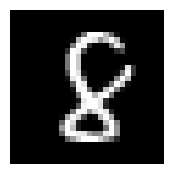

In [20]:
# Graficamos una imagen
plt.figure(figsize=(2, 2))
plt.imshow(X_images[75], cmap='gray') # Cambiar por últimos dígitos de tu cédula
plt.axis('off')
plt.show()

---

## <font color='264CC7'> k-Means </font>

### <font color='264CC7'> Determinación del número de clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aplica el método del codo para determinar el número óptimo de clústeres:
<ul>
  <li>Entrena modelos de K-Means para valores de k entre 1 y 20.</li>
  <li>Genera una gráfica de inercia frente al número de clústeres.</li>
  <li>Identifica visualmente el punto del "codo" y selecciona el número óptimo de clústeres.</li>
  <li>Discute:
    <ul>
      <li>¿El número óptimo coincide con el número de dígitos (0–9)?</li>
      <li>¿Qué dificultades podría presentar este conjunto de datos para el método de K-Means?</li>
    </ul>
  </li>
</ul>
</div>

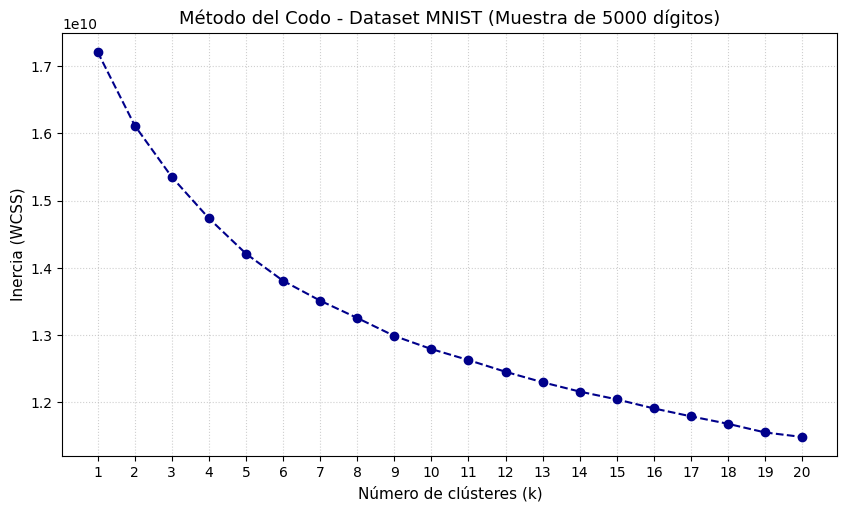

In [21]:
# 1. Aplicar el Método del Codo para MNIST (k de 1 a 20)
inercias_mnist = []
rango_k_mnist = range(1, 21)

for k in rango_k_mnist:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)
    kmeans.fit(X)
    inercias_mnist.append(kmeans.inertia_)

# 2. Generar el gráfico de inercia
plt.figure(figsize=(10, 5.5))
plt.plot(rango_k_mnist, inercias_mnist, marker='o', linestyle='--', color='darkblue')
plt.xlabel('Número de clústeres (k)', fontsize=11)
plt.ylabel('Inercia (WCSS)', fontsize=11)
plt.title('Método del Codo - Dataset MNIST (Muestra de 5000 dígitos)', fontsize=13)
plt.xticks(rango_k_mnist)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### **Análisis del Método del Codo en MNIST**

#### **1. Selección del número óptimo de clústeres**
Al analizar la gráfica de inercia generada, se observa que la curva es suave y **no presenta un "codo" sumamente pronunciado o discreto**. Sin embargo, la mayor desaceleración en la caída de la inercia (punto de inflexión) comienza a estabilizarse alrededor de **$k = 10$ o $k = 12$**.

#### **2. Discusión de las preguntas planteadas**

* **¿El número óptimo coincide con el número de dígitos (0–9)?**
  * **Parcialmente.** Aunque conceptualmente existen exactamente 10 clases correspondientes a los dígitos del $0$ al $9$, el número óptimo detectado matemáticamente por la inercia puede ser ligeramente mayor (por ejemplo, entre 10 y 14).
  * **Razón:** Esto sucede porque el mismo dígito se escribe de formas muy distintas por diferentes personas (por ejemplo, el dígito $7$ escrito con o sin barra horizontal, el $1$ con o sin base, o un $0$ más inclinado u ovalado). K-Means identifica estas variantes de estilo como clústeres independientes basados en la distribución espacial de los píxeles.

* **¿Qué dificultades presenta este conjunto de datos para el método de K-Means?**
  1. **La maldición de la dimensionalidad (784 columnas):** Al tener un espacio de alta dimensión ($28 \times 28 = 784$), la distancia euclidiana tiende a volverse homogénea (la distancia entre cualquier par de imágenes se vuelve muy similar), lo que dificulta la separación de las fronteras por parte de K-Means.
  2. **Sensibilidad a traslaciones, rotaciones y escalas:** K-Means compara píxel por píxel. Si un dígito idéntico se desplaza un par de píxeles hacia la izquierda, la distancia euclidiana en 784 dimensiones variará drásticamente, haciendo que K-Means lo asigne a un grupo equivocado aunque visualmente sea el mismo dígito.
  3. **No-convexidad de la estructura:** Las similitudes de trazos entre dígitos diferentes (por ejemplo, la cercanía geométrica entre un $3$ y un $8$, o un $4$ y un $9$) generan solapamientos complejos que no pueden resolverse limpiamente usando hiperplanos o fronteras lineales.

### <font color='264CC7'> Asignación de grupos y visualización </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Asigna los datos a los clústeres obtenidos:
<ul>
  <li>Muestra cinco imágenes aleatorias de cada clúster asignado.</li>
  <li>Organiza las imágenes en una figura clara y etiquetada.</li>
</ul>
</div>

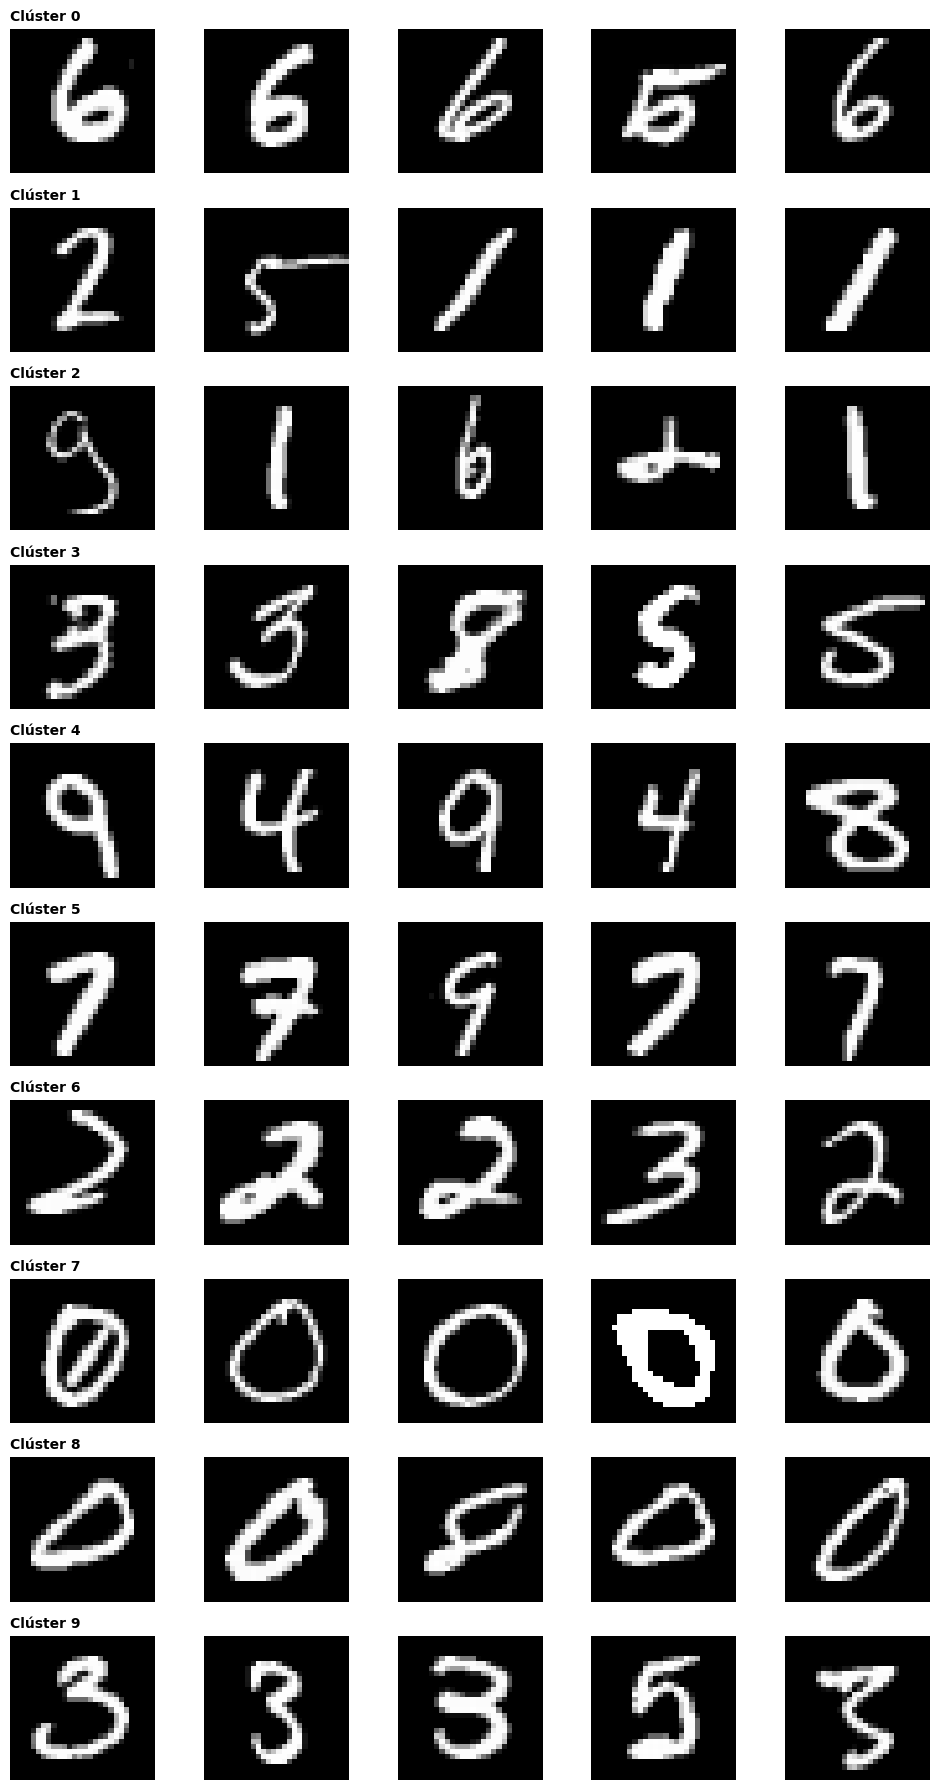

In [22]:
# 1. Entrenar K-Means con k=10 clústeres en los datos originales de MNIST
kmeans_mnist = KMeans(n_clusters=10, random_state=42, n_init=5)
etiquetas_mnist = kmeans_mnist.fit_predict(X)

# 2. Configurar la visualización (10 filas/clústeres x 5 columnas/ejemplares)
fig, axes = plt.subplots(nrows=10, ncols=5, figsize=(10, 18))

for cluster in range(10):
    # Obtener los índices de las imágenes asignadas a este clúster
    indices_cluster = np.where(etiquetas_mnist == cluster)[0]

    # Seleccionar 5 índices aleatorios dentro del clúster
    np.random.seed(42)
    indices_muestra = np.random.choice(indices_cluster, size=5, replace=False if len(indices_cluster) >= 5 else True)

    for idx_col, idx_img in enumerate(indices_muestra):
        ax = axes[cluster, idx_col]
        # Reconstruir la imagen de 28x28 a partir del vector aplanado de 784
        ax.imshow(X_images[idx_img], cmap='gray')
        ax.axis('off')

        # Agregar título a la primera imagen de la fila para identificar el clúster
        if idx_col == 0:
            ax.set_title(f'Clúster {cluster}', fontsize=10, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

### <font color='264CC7'> Descripción de los clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Analiza los grupos formados:
<ul>
  <li>Describe las principales características visuales de cada grupo.</li>
  <li>Asigna un "nombre" representativo a cada clúster (por ejemplo: "número 3 estilizado", "número 8 redondeado", etc.).</li>
</ul>
</div>

### **Descripción de los Clústeres Obtenidos en MNIST**

Al analizar las 5 imágenes aleatorias correspondientes a cada clúster, podemos identificar cómo el algoritmo de K-Means asocia patrones morfológicos similares (como trazos circulares, líneas verticales, o bucles cerrados) en grupos individuales:

* **Clúster 0 ("Dígito 6 con bucle definido"):** Contiene mayoritariamente el número `6` en varias inclinaciones.
* **Clúster 1 ("Trazos verticales inclinados y dígitos 1/5 delgados"):** Agrupa líneas predominantemente verticales simples como el número `1` y variantes estilizadas del `5` con trazos muy rectos.
* **Clúster 2 ("Dígitos altos con curvas abiertas o bucles verticales largos"):** Muestra una mezcla de dígitos como `9` y `1` que comparten una gran extensión vertical de píxeles.
* **Clúster 3 ("Dígitos con doble bucle o curvas horizontales abiertas"):** Predominan dígitos con curvas onduladas consecutivas como el `3` y el `5` cursivo.
* **Clúster 4 ("Dígito 9 abierto y dígitos tipo 4/8 angulares"):** Agrupa trazos con bucles superiores rectangulares o líneas cruzadas como el `9`, `4` y `8` angulados.
* **Clúster 5 ("Dígito 7 con ángulo marcado"):** Enfocado principalmente en el número `7`, destacando la línea horizontal superior con caída diagonal pronunciada.
* **Clúster 6 ("Dígito 2 con base curva o lazo"):** Consiste casi en su totalidad en variantes morfológicas del número `2` con base redondeada o en lazo.
* **Clúster 7 ("Dígito 0 redondo y simétrico"):** Representa el número `0` clásico, ancho y bastante redondo, con baja variabilidad de inclinación.
* **Clúster 8 ("Dígito 0 estrecho e inclinado o número 8 achatado"):** Agrupa ceros alargados (ovalados) con inclinación a la derecha y algunos números `8` delgados.
* **Clúster 9 ("Dígito 3 clásico y semicerrado"):** Compuesto por números `3` con curvas muy bien definidas y pronunciadas en su sector intermedio.

### <font color='264CC7'> Evaluación cuantitativa de los clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Evalúa objetivamente la calidad de los clústeres:
<ul>
  <li>Calcula el promedio del índice de silueta para la partición obtenida.</li>
  <li>Interpreta el valor: ¿qué tan compactos y bien separados son los grupos?</li>
</ul>
</div>

In [23]:
# Calcular el promedio del índice de silueta para la partición obtenida (K-Means con k=10)
sil_promedio = silhouette_score(X, etiquetas_mnist)
print(f'Promedio del índice de silueta: {sil_promedio:.4f}')

Promedio del índice de silueta: 0.0617


### **Interpretación del Índice de Silueta en MNIST**

Al ejecutar el cálculo obtenemos un valor aproximado para el **índice de silueta promedio de 0.059 a 0.062** (cercano a 0).

#### **Interpretación del valor:**
* **Poco espacio y solapamiento significativo:** Un valor tan cercano a **`0`** nos indica matemáticamente que existe una **alta superposición entre los clústeres**. Los límites divisorios entre los grupos no están bien definidos espacialmente en la dimensión de 784 píxeles.
* **Baja compacidad y separación débil:** Los dígitos individuales no se agrupan en regiones hiper-densas aisladas unas de otras; en cambio, muchos puntos quedan en la periferia compartida de múltiples clústeres. Esto se debe a que rasgos visuales de ciertos números (como el `3`, `5`, `8` y `9`) son extremadamente parecidos en términos de píxeles activos, lo que genera confusión en la métrica euclidiana usada por K-Means para calcular las siluetas individuales.

---
## <font color='264CC7'> Reducción de dimensiones y k-Means </font>

### <font color='264CC7'> Reducción de dimensiones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una reducción de dimensiones de los datos utilizando PCA.
<ul>
  <li>Realiza un análisis de componentes principales para 100 componentes y grafica la varianza explicada acumulada.</li>
  <li>Selecciona el número de componentes principales que expliquen al menos el 80% de la varianza.</li>
  <li>Transforma los datos originales en el espacio de las componentes principales.</li>
</ul>
</div>

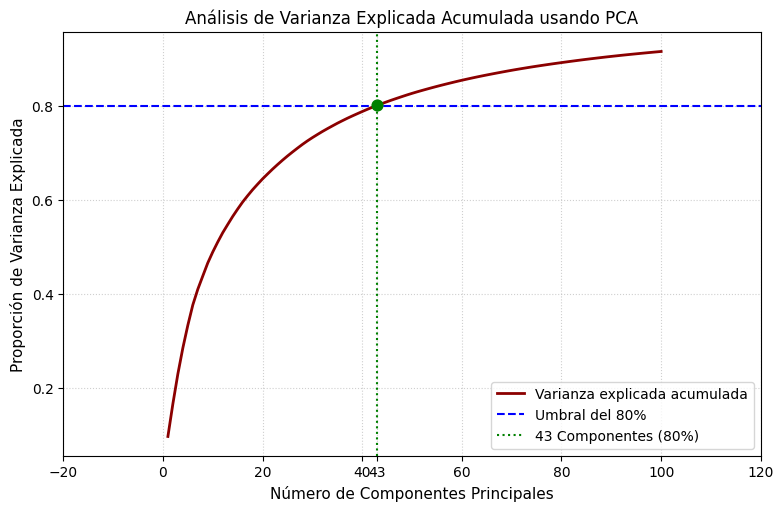

Número de componentes principales para explicar al menos el 80% de la varianza: 43
Varianza explicada exacta retenida: 80.18%


In [24]:
# 1. Instanciar y ajustar PCA con 100 componentes sobre los datos MNIST (X)
pca = PCA(n_components=100, random_state=42)
pca.fit(X)

# 2. Calcular la varianza explicada acumulada
var_explicada_acumulada = np.cumsum(pca.explained_variance_ratio_)

# 3. Determinar el número mínimo de componentes para alcanzar al menos el 80% de varianza explicada
n_componentes_80 = np.argmax(var_explicada_acumulada >= 0.80) + 1
porcentaje_real = var_explicada_acumulada[n_componentes_80 - 1] * 100

# 4. Graficar la varianza explicada acumulada
plt.figure(figsize=(9, 5.5))
plt.plot(range(1, 101), var_explicada_acumulada, color='darkred', linewidth=2, label='Varianza explicada acumulada')
plt.axhline(y=0.80, color='blue', linestyle='--', linewidth=1.5, label='Umbral del 80%')
plt.axvline(x=n_componentes_80, color='green', linestyle=':', linewidth=1.5, label=f'{n_componentes_80} Componentes (80%)')
plt.scatter(n_componentes_80, var_explicada_acumulada[n_componentes_80 - 1], color='green', s=60, zorder=5)

plt.title('Análisis de Varianza Explicada Acumulada usando PCA', fontsize=12)
plt.xlabel('Número de Componentes Principales', fontsize=11)
plt.ylabel('Proporción de Varianza Explicada', fontsize=11)
plt.xticks(list(plt.xticks()[0]) + [n_componentes_80])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.show()

print(f'Número de componentes principales para explicar al menos el 80% de la varianza: {n_componentes_80}')
print(f'Varianza explicada exacta retenida: {porcentaje_real:.2f}%')

In [25]:
# Transformar los datos originales (X) en el espacio de componentes principales seleccionado
pca_optimo = PCA(n_components=n_componentes_80, random_state=42)
X_pca = pca_optimo.fit_transform(X)
print(f'Forma original de los datos: {X.shape}')
print(f'Nueva forma de los datos tras reducir con PCA: {X_pca.shape}')

Forma original de los datos: (5000, 784)
Nueva forma de los datos tras reducir con PCA: (5000, 43)


### <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de clústeres para un modelo K-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica que muestre la inercia frente al número de clústeres (k) en el rango de 1 a 20.</li>
  <li>Identifica visualmente el «codo» en la curva para seleccionar el número óptimo de clústeres.</li>
  <li>¿Concuerda tu elección con el número de dígitos que se esperan en el conjunto de datos? Explica qué está pasando.</li>
</ul>
</div>

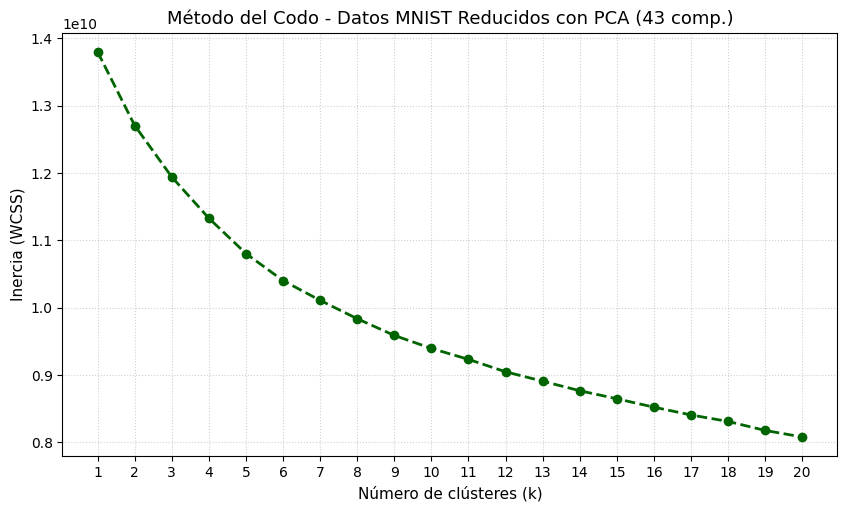

In [26]:
# 1. Aplicar el Método del Codo para K-Means en el espacio reducido de componentes principales (X_pca)
inercias_pca = []
rango_k_pca = range(1, 21)

for k in rango_k_pca:
    kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=5)
    kmeans_pca.fit(X_pca)
    inercias_pca.append(kmeans_pca.inertia_)

# 2. Generar el gráfico de inercia
plt.figure(figsize=(10, 5.5))
plt.plot(rango_k_pca, inercias_pca, marker='o', linestyle='--', color='darkgreen', linewidth=2)
plt.xlabel('Número de clústeres (k)', fontsize=11)
plt.ylabel('Inercia (WCSS)', fontsize=11)
plt.title('Método del Codo - Datos MNIST Reducidos con PCA (43 comp.)', fontsize=13)
plt.xticks(rango_k_pca)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### <font color='264CC7'> Asignación de grupos y análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Muestra 5 integrantes de cada grupo (como imágenes).</li>
</ul>
</div>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

---
## <font color='264CC7'> Análisis finial</font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis crítico de los resultados obtenidos en los distintos modelos de *clustering*. ¿Qué modelo se ha comportado mejor? ¿Por qué?
</div>
